# Manchas de Inundação

In [1]:
import geopandas as gpd
import numpy as np
import rasterio
from rasterio.features import rasterize
from rasterio.windows import from_bounds
from rasterio.warp import reproject
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
import os

## Carregar Shapefiles das Manchas

In [2]:
pasta = '../dados/manchas-inundacao'

manchas = {
    "Q2": {
        "arquivo": "Q2_max.shp",
        "peso": 4.0
    },
    "Q10": {
        "arquivo": "Q10_max.shp",
        "peso": 3.0
    },
    "Q25": {
        "arquivo": "Q25_max.shp",
        "peso": 2.0
    },
    "Q50": {
        "arquivo": "Q50_max.shp",
        "peso": 1.0
    },
    "Q100": {
        "arquivo": "Q100_max.shp",
        "peso": 0.5
    }
}

gdfs = dict()

for nome, config in manchas.items():
    caminho = os.path.join(pasta, config['arquivo'])
    
    if os.path.exists(caminho):
        gdfs[nome] = gpd.read_file(caminho)
        print(f"Carregado: {nome}")
    else:
        print(f"Arquivo não encontrado: {caminho}")

C:\Users\ezequ\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Carregado: Q2
Carregado: Q10
Carregado: Q25
Carregado: Q50
Carregado: Q100


## Visualização das Manchas Individuais

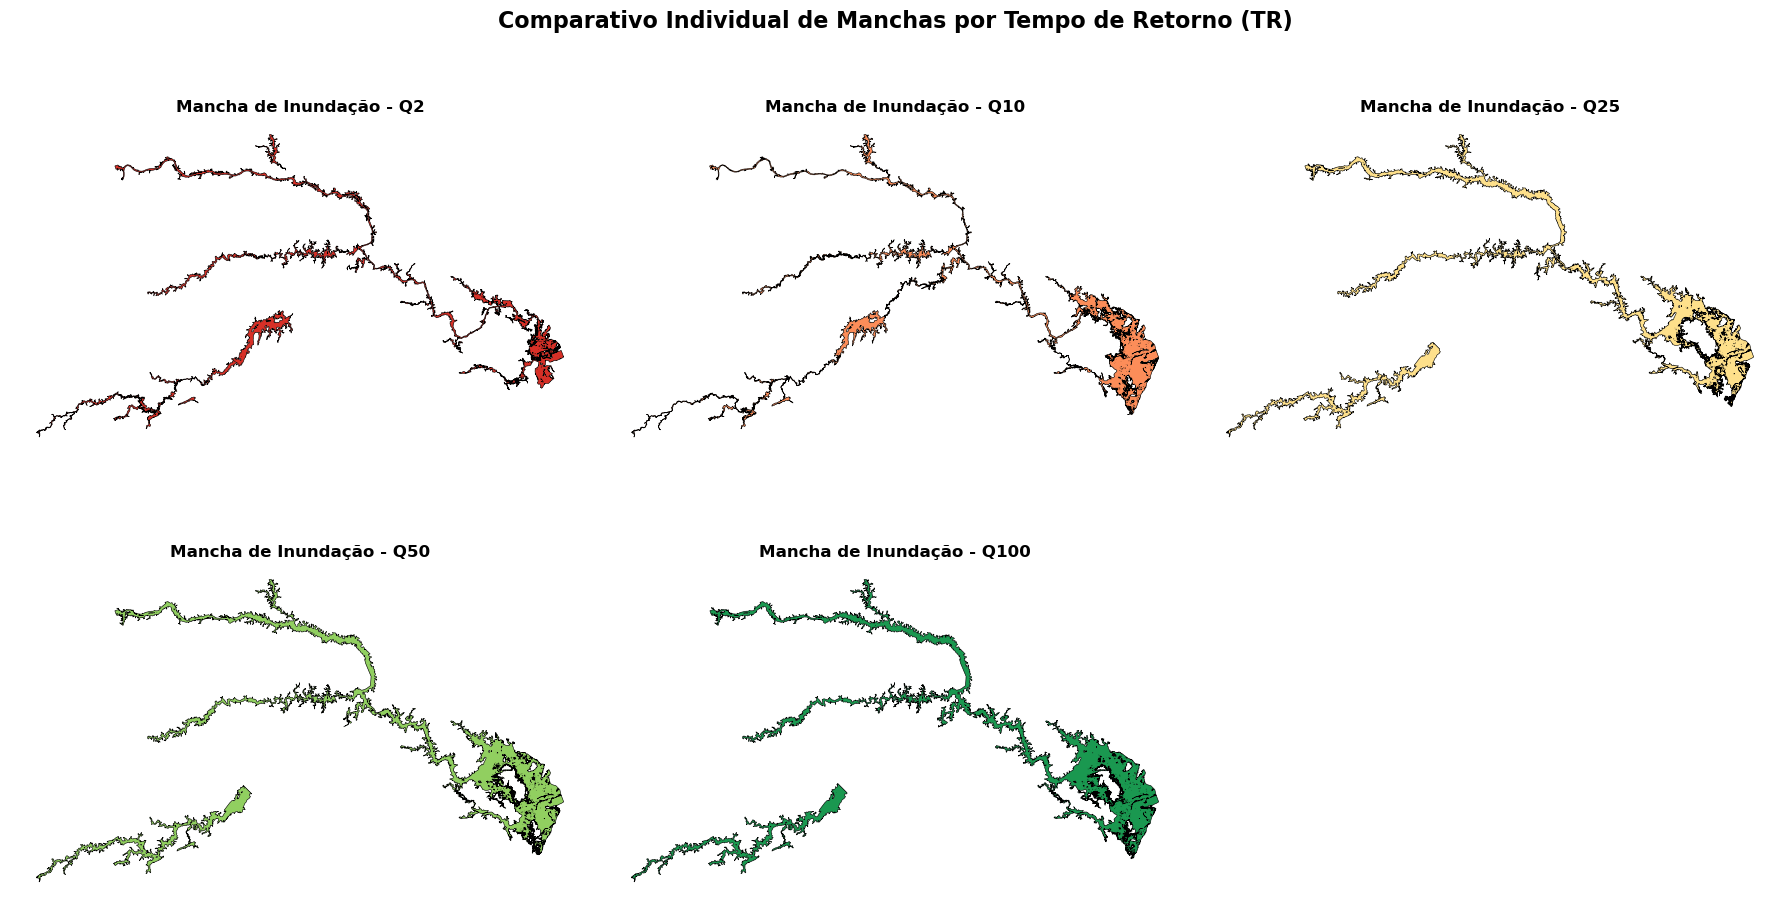

In [5]:
cores = {
    "Q2": "#d73027",
    "Q10": "#fc8d59",
    "Q25": "#fee08b",
    "Q50": "#91cf60",
    "Q100": "#1a9850"
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (rotulo, gdf) in enumerate(gdfs.items()):
    ax = axes[i]

    gdf.plot(
        ax=ax,
        color=cores.get(rotulo, "gray"),
        edgecolor="black",
        linewidth=0.4
    )

    ax.set_title(
        f"Mancha de Inundação - {rotulo}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_axis_off()

for i in range(len(gdfs), len(axes)):
    axes[i].set_visible(False)

plt.suptitle(
    "Comparativo Individual de Manchas por Tempo de Retorno (TR)",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

plt.tight_layout()
plt.show()

## Criar Raster com Todas as Manchas

In [6]:
crs = gdfs["Q2"].crs

for nome, gdf in gdfs.items():
    if gdf.crs != crs:
        gdfs[nome] = gdf.to_crs(crs)

bounds = [
    gdf.total_bounds
    for gdf in gdfs.values()
]

minx = min(b[0] for b in bounds)
miny = min(b[1] for b in bounds)
maxx = max(b[2] for b in bounds)
maxy = max(b[3] for b in bounds)

# Resolução do raster
res = 30  # metros

width = int(np.ceil((maxx - minx) / res))
height = int(np.ceil((maxy - miny) / res))

transform = rasterio.transform.from_origin(
    minx,
    maxy,
    res,
    res
)

In [7]:
raster_final = np.zeros(
    (height, width),
    dtype=np.float32
)

# Processar os dados do menor peso para o maior
for nome in ["Q100", "Q50", "Q25", "Q10", "Q2"]:

    config = manchas[nome]
    gdf = gdfs[nome]

    raster = rasterize(
        [(geom, config['peso']) for geom in gdf.geometry],
        out_shape=(height, width),
        transform=transform,
        fill=0,
        dtype=np.float32
    )

    mask = raster > 0

    raster_final[mask] = raster[mask]

with rasterio.open(
    "../dados/manchas-inundacao/mancha_ponderada.tif",
    "w",
    driver="GTiff",
    height=height,
    width=width,
    count=1,
    dtype=raster_final.dtype,
    crs=crs,
    transform=transform,
    nodata=0
) as dst:

    dst.write(raster_final, 1)

print("Raster criado com sucesso!")

Raster criado com sucesso!


## Visualizar Raster das Manchas

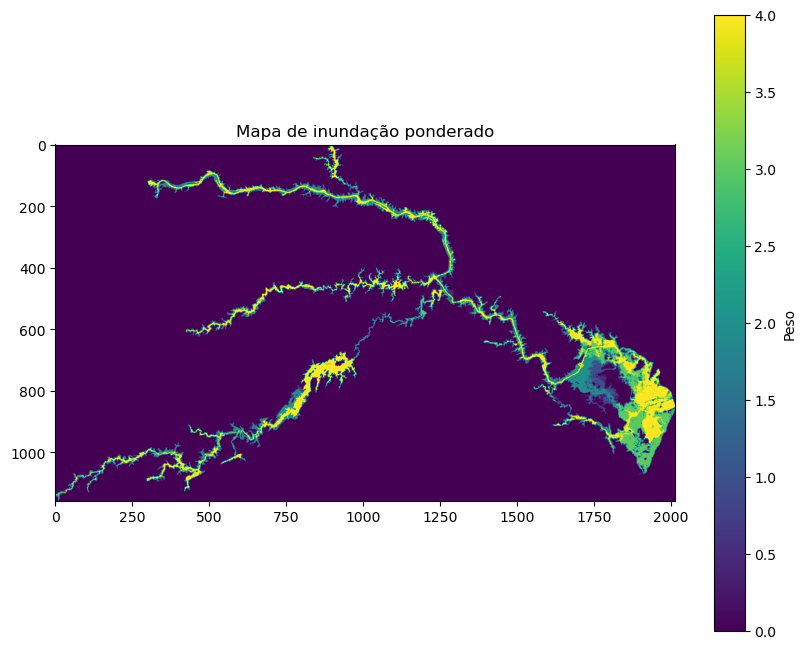

In [8]:
with rasterio.open('../dados/manchas-inundacao/mancha_ponderada.tif') as src:
    raster = src.read(1)

plt.figure(figsize=(10, 8))

plt.imshow(raster, vmin=0, vmax=4)
plt.colorbar(label="Peso")
plt.title("Mapa de inundação ponderado")

plt.show()

## Recortar Raster para cidade de Recife

In [9]:
MOLDURA = '../dados/rasters/moldura-recife.tif'
ENTRADA = '../dados/manchas-inundacao/mancha_ponderada.tif'
SAIDA = '../dados/manchas-inundacao/mancha_recife.tif'


with rasterio.open(MOLDURA) as moldura:

    moldura_data = moldura.read(1)

    dst_height = moldura.height
    dst_width = moldura.width
    dst_transform = moldura.transform
    dst_crs = moldura.crs
    dst_profile = moldura.profile.copy()

    print("MOLDURA")
    print(f"CRS: {dst_crs}")
    print(f"Dimensão: {dst_width} x {dst_height}")
    print(f"Resolução: {moldura.res}")
    print(f"Bounds: {moldura.bounds}")


with rasterio.open(ENTRADA) as src:
    print("\nENTRADA")
    print(f"CRS: {src.crs}")
    print(f"Dimensão: {src.width} x {src.height}")
    print(f"Resolução: {src.res}")

    raster_recife = np.zeros(
        (dst_height, dst_width),
        dtype=src.dtypes[0]
    )

    reproject(
        source=rasterio.band(src, 1),
        destination=raster_recife,

        src_transform=src.transform,
        src_crs=src.crs,

        dst_transform=dst_transform,
        dst_crs=dst_crs,

        resampling=Resampling.nearest
    )

dst_profile.update(
    dtype=raster_recife.dtype,
    count=1,
    compress='lzw'
)

with rasterio.open(SAIDA, 'w', **dst_profile) as dst:
    dst.write(raster_recife, 1)


print("\nRaster criado com sucesso!")
print(f"Dimensão: {dst_width} x {dst_height}")
print(f"Arquivo: {SAIDA}")

MOLDURA
CRS: EPSG:31985
Dimensão: 646 x 898
Resolução: (30.0, 30.0)
Bounds: BoundingBox(left=276747.7872667955, bottom=9097058.175284462, right=296127.7872667955, top=9123998.175284462)

ENTRADA
CRS: EPSG:31985
Dimensão: 2015 x 1157
Resolução: (30.0, 30.0)

Raster criado com sucesso!
Dimensão: 646 x 898
Arquivo: ../dados/manchas-inundacao/mancha_recife.tif


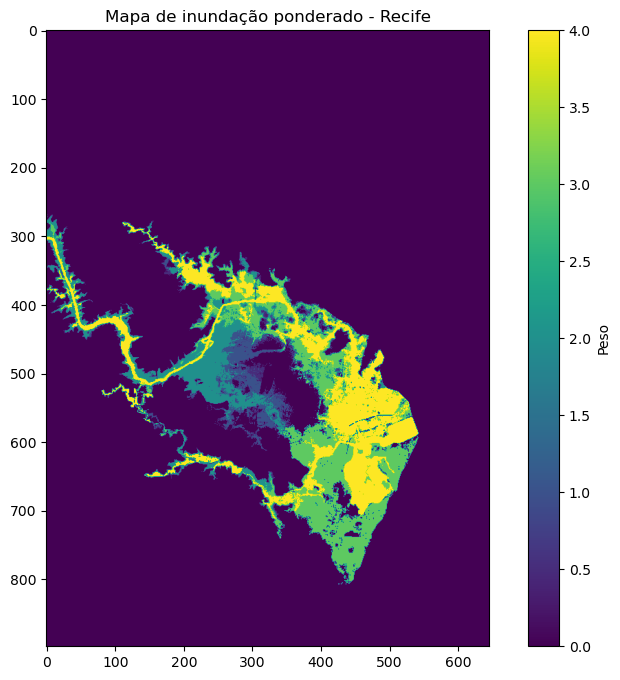

In [10]:
with rasterio.open(SAIDA) as src:
    raster = src.read(1)

plt.figure(figsize=(10, 8))

plt.imshow(raster, vmin=0, vmax=4)
plt.colorbar(label="Peso")
plt.title("Mapa de inundação ponderado - Recife")

plt.show()